# 07. Cascade Spread Prediction & Virality Regression

- **Role/Owner:** Member 3 (Analytics, Graph & Visualization Lead)
- **Core Responsibility:** Train a Ridge Regression model that predicts how large a rumour cascade will become, using only facts about the author of the first tweet (followers, verified badge).
- **Key Interface/Contract:** Consumes `backend/data/processed/cascade_features.csv`; outputs `backend/models/spread_regressor.joblib` (read by `app/services/cascade.py`) and `backend/reports/spread_metrics.json`.

**What this notebook does**

1. Load the 6,425 PHEME cascades and use the same `split` column as the text models, so every model sees the same partition.
2. Choose the target (`cascade_size`, log-transformed because it is very skewed).
3. Choose features. Only information that is known *before* the cascade grows is allowed. Columns that are a result of the cascade (`max_depth`, `reply_count`, `n_unique_verified`) would leak the answer and are left out.
4. Compare Ridge with a "predict the average" baseline, tune the penalty `alpha` on the validation set, and report the test set once.
5. Repeat the test on events the model has never seen (leave-one-event-out), the same idea as the text baselines in `split_baselines.md`.
6. Turn predictions into Low / Moderate / High spread risk and save the model.

## 1. Setup

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
DATA = ROOT / "backend" / "data" / "processed"
MODELS = ROOT / "backend" / "models"
REPORTS = ROOT / "backend" / "reports"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: c:\Users\Admin\Documents\COS30049-political-misinfo


## 2. Load the cascades and check the splits

`cascade_features.csv` has one row per cascade. The `split` column has five values: `train`, `val`, `test`, `excluded_label` and `excluded_dup`.

- `train / val / test` are the cascades whose source tweet is in the text-model splits. We use these.
- `excluded_label` are cascades dropped by the label rules (unverified rumours and two almost-all-false events). Spread prediction does not need the true/false label, so they could still be used for training. We test that as **Experiment B** and keep it out of the main model so the comparison with the other notebooks stays fair.
- `excluded_dup` are cascades whose source text was a duplicate. We never use them, because a duplicate could appear in both train and test.

In [2]:
df = pd.read_csv(DATA / "cascade_features.csv")
assert len(df) == 6425, f"expected 6,425 cascades, found {len(df):,}"
needed = {"cascade_id", "label", "veracity", "event", "split", "cascade_size",
          "max_depth", "reply_count", "root_user_followers", "root_user_verified", "n_unique_verified"}
assert needed <= set(df.columns), f"missing columns: {needed - set(df.columns)}"

print(df["split"].value_counts().to_string())
print()
print(pd.crosstab(df["split"], df["veracity"]))
df.head()

split
train             3757
excluded_label     937
test               805
val                805
excluded_dup       121

veracity        false  non-rumour  true  unverified
split                                              
excluded_dup        8          88    25           0
excluded_label    236           4     0         697
test               59         588   158           0
train             276        2757   724           0
val                59         586   160           0


,cascade_id,label,veracity,event,split,cascade_size,max_depth,reply_count,root_user_followers,root_user_verified,n_unique_verified
0,500388199064420352,1,unverified,ferguson-all-rnr-threads,excluded_label,27,4,13,19415,0,0
1,500421926079066112,1,false,ferguson-all-rnr-threads,train,15,3,11,21711,0,0
2,500360596995731456,1,unverified,ferguson-all-rnr-threads,excluded_label,16,2,13,185071,1,1
3,500359312447787009,1,unverified,ferguson-all-rnr-threads,excluded_label,9,3,7,8033,1,2
4,500251535943942145,1,unverified,ferguson-all-rnr-threads,excluded_label,10,2,8,7975,0,0


In [3]:
USED = ["train", "val", "test"]
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()
extra = df[df["split"] == "excluded_label"].copy()   # only for Experiment B

for name, d in [("train", train), ("val", val), ("test", test), ("excluded_label", extra)]:
    print(f"{name:15s} {len(d):5d} cascades | median size {d['cascade_size'].median():.0f}")

train            3757 cascades | median size 13
val               805 cascades | median size 12
test              805 cascades | median size 13
excluded_label    937 cascades | median size 9


## 3. Target: cascade size

`cascade_size` is the number of tweets in the reply tree (the source tweet plus everything that grew from it). The histogram below shows that most cascades are small and a few are very large, so a model trained on the raw number would be pulled around by a handful of outliers. We train on `log1p(cascade_size)` and convert back with `expm1` when we need real tweet counts.

Note: these cascades are small. The typical cascade has about 12 tweets, so the "thousands of users" thresholds we imagined in the planning documents do not fit this dataset. Risk levels are therefore defined from the data in Section 9.

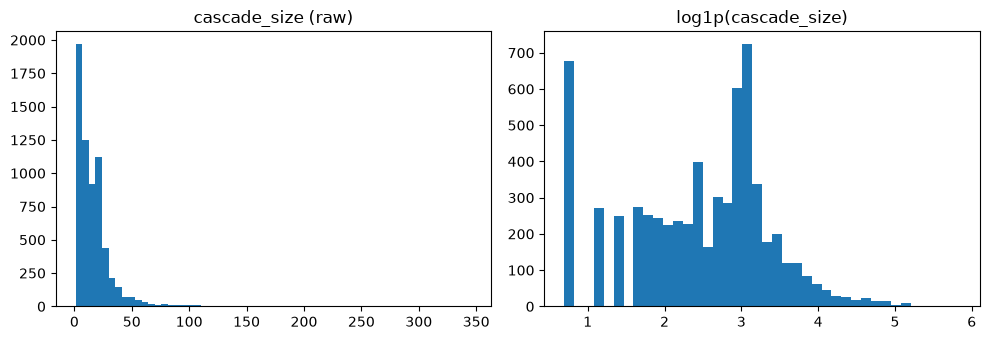

count    6425.0
mean       16.5
std        19.8
min         1.0
50%        12.0
75%        21.0
90%        32.0
99%        99.8
max       346.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df["cascade_size"], bins=60)
ax[0].set_title("cascade_size (raw)")
ax[1].hist(np.log1p(df["cascade_size"]), bins=40)
ax[1].set_title("log1p(cascade_size)")
plt.tight_layout()
plt.show()
print(df["cascade_size"].describe(percentiles=[.5, .75, .9, .99]).round(1).to_string())

## 4. Features, and why some columns are not allowed

At prediction time the dashboard only knows the author of the post: how many followers they have and whether they are verified. So the model may only use:

| Column | Use | Reason |
|---|---|---|
| `root_user_followers` | feature (log-transformed) | known before the cascade starts |
| `root_user_verified` | feature | known before the cascade starts |
| `max_depth`, `reply_count`, `n_unique_verified` | **not used** | measured *from* the finished cascade, so they leak the target |
| `label`, `veracity` | not used | not known for a new claim (the dashboard predicts veracity with a separate model) |
| `event` | not used for training | a new claim has no event label; used only to test on unseen events |

The correlation table shows the problem: `max_depth` and `reply_count` correlate very strongly with the size (about 0.84 and 0.79), while the author columns correlate only weakly (about 0.18 and 0.11). `n_unique_verified` has a weaker correlation (about 0.19), but it is counted from the people who joined the finished cascade, so it is not known in advance either and stays out.

In [5]:
candidates = ["root_user_followers", "root_user_verified", "max_depth", "reply_count", "n_unique_verified"]
pool = df[df["split"].isin(USED)]
corr = (pool[["cascade_size"] + candidates].corr(method="spearman")["cascade_size"]
        .drop("cascade_size").round(3).rename("spearman vs cascade_size"))
corr.to_frame()

,spearman vs cascade_size
root_user_followers,0.182
root_user_verified,0.105
max_depth,0.837
reply_count,0.793
n_unique_verified,0.188


## 5. Model, metrics and baseline

The model is a scikit-learn pipeline: log-transform and standardise the follower count, pass the verified flag through, then Ridge regression. Putting the log-transform inside the pipeline means the API can send the raw follower number and does not need to repeat the maths.

Metrics (all on the test or validation set, never on training data):

- **R2 (log scale)**: share of variance explained. 0 means "no better than predicting the average".
- **MAE (tweets)**: average error in real tweet counts.
- **Spearman**: does the model at least rank big cascades above small ones? This matters for risk levels.

The baseline always predicts the training average. Ridge has to beat it to be worth using.

In [6]:
FEATURES = ["root_user_followers", "root_user_verified"]


def make_pipeline(alpha):
    prep = ColumnTransformer([
        ("followers", Pipeline([("log", FunctionTransformer(np.log1p)),
                                ("scale", StandardScaler())]), ["root_user_followers"]),
        ("verified", "passthrough", ["root_user_verified"]),
    ])
    return Pipeline([("prep", prep), ("ridge", Ridge(alpha=alpha))])


def rank_corr(a, b):
    return float("nan") if np.ptp(b) < 1e-9 else float(spearmanr(a, b)[0])


def evaluate(model, d):
    y_log = np.log1p(d["cascade_size"].to_numpy())
    p_log = model.predict(d[FEATURES])
    p_size = np.expm1(p_log)
    return {
        "r2_log": float(r2_score(y_log, p_log)),
        "mae_log": float(mean_absolute_error(y_log, p_log)),
        "mae_size": float(mean_absolute_error(d["cascade_size"], p_size)),
        "rmse_size": float(np.sqrt(mean_squared_error(d["cascade_size"], p_size))),
        "spearman": rank_corr(d["cascade_size"], p_log),
    }


y_train = np.log1p(train["cascade_size"])
baseline = DummyRegressor(strategy="mean").fit(train[FEATURES], y_train)
print("baseline fitted: always predicts", round(float(np.expm1(baseline.constant_[0][0])), 1), "tweets")

baseline fitted: always predicts 11.1 tweets


### Choosing the penalty `alpha`

Ridge adds a penalty on large coefficients. A bigger `alpha` means a simpler, more cautious model. We try 13 values from 0.01 to 10,000 and pick the one with the best R2 on the **validation** set. The test set is not touched here.

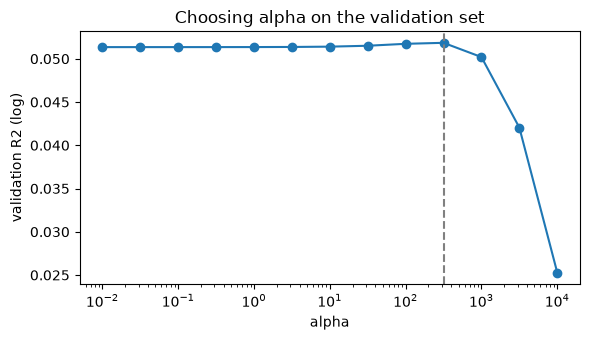

best alpha: 316.22776601683796


,alpha,r2_log,mae_log,mae_size,rmse_size,spearman
0,0.0100,0.0513,0.7104,9.8591,15.9920,0.2038
1,0.0316,0.0513,0.7104,9.8591,15.9920,0.2038
2,0.1000,0.0513,0.7104,9.8591,15.9920,0.2039
3,0.3162,0.0513,0.7104,9.8591,15.9920,0.2039
4,1.0000,0.0514,0.7104,9.8592,15.9920,0.2039
5,3.1623,0.0514,0.7104,9.8593,15.9921,0.2038
6,10.0000,0.0514,0.7104,9.8597,15.9922,0.2038
7,31.6228,0.0515,0.7105,9.8609,15.9926,0.2036
8,100.0000,0.0517,0.7107,9.8648,15.9941,0.2035
9,316.2278,0.0518,0.7115,9.8779,15.9988,0.2045


In [7]:
alphas = np.logspace(-2, 4, 13)
rows = []
for a in alphas:
    m = make_pipeline(a).fit(train[FEATURES], y_train)
    rows.append({"alpha": float(a), **evaluate(m, val)})
alpha_df = pd.DataFrame(rows)
best_alpha = float(alpha_df.sort_values("r2_log", ascending=False).iloc[0]["alpha"])

plt.figure(figsize=(6, 3.5))
plt.semilogx(alpha_df["alpha"], alpha_df["r2_log"], marker="o")
plt.axvline(best_alpha, linestyle="--", color="gray")
plt.xlabel("alpha")
plt.ylabel("validation R2 (log)")
plt.title("Choosing alpha on the validation set")
plt.tight_layout()
plt.show()
print("best alpha:", best_alpha)
alpha_df.round(4)

In [8]:
model = make_pipeline(best_alpha).fit(train[FEATURES], y_train)

results = pd.DataFrame({
    "baseline val": evaluate(baseline, val),
    "baseline test": evaluate(baseline, test),
    "ridge val": evaluate(model, val),
    "ridge test": evaluate(model, test),
}).T.round(3)
results

,r2_log,mae_log,mae_size,rmse_size,spearman
baseline val,-0.001,0.739,10.227,16.199,NaN
baseline test,-0.000,0.745,11.516,21.616,NaN
ridge val,0.052,0.711,9.878,15.999,0.204
ridge test,0.040,0.728,11.293,21.510,0.157


## 6. Experiment B: add the `excluded_label` cascades to training

Spread prediction does not need to know whether a rumour is true, so the 937 `excluded_label` cascades are valid data. We add them to the training set only (validation and test stay the same) and see whether more data helps. If the result is about the same, the simpler setup from Section 5 stays as the main model.

In [9]:
train_b = pd.concat([train, extra])
model_b = make_pipeline(best_alpha).fit(train_b[FEATURES], np.log1p(train_b["cascade_size"]))
exp_b = pd.DataFrame({
    "A: train only (val)": evaluate(model, val),
    "B: train + excluded_label (val)": evaluate(model_b, val),
    "A: train only (test)": evaluate(model, test),
    "B: train + excluded_label (test)": evaluate(model_b, test),
}).T.round(3)
exp_b

,r2_log,mae_log,mae_size,rmse_size,spearman
A: train only (val),0.052,0.711,9.878,15.999,0.204
B: train + excluded_label (val),0.053,0.714,9.905,16.179,0.204
A: train only (test),0.040,0.728,11.293,21.510,0.157
B: train + excluded_label (test),0.030,0.733,11.349,21.700,0.157


## 7. Events the model has never seen

The text baselines in `split_baselines.md` score much lower on events they never saw than on a random split, because they partly learn the event. The same risk applies here: some events (for example Charlie Hebdo) produce bigger cascades than others. We hold out one event at a time, fit on all other events, and test on the held-out one. Only events with at least 400 cascades are held out. We report both numbers, as agreed in the team notes.

In [10]:
big_events = pool["event"].value_counts()
big_events = big_events[big_events >= 400].index.tolist()

rows = []
for ev in big_events:
    a, b = pool[pool["event"] != ev], pool[pool["event"] == ev]
    ya = np.log1p(a["cascade_size"])
    m = make_pipeline(best_alpha).fit(a[FEATURES], ya)
    dm = DummyRegressor(strategy="mean").fit(a[FEATURES], ya)
    r, d = evaluate(m, b), evaluate(dm, b)
    rows.append({"held-out event": ev, "cascades": len(b),
                 "ridge R2": r["r2_log"], "baseline R2": d["r2_log"],
                 "ridge MAE": r["mae_size"], "baseline MAE": d["mae_size"],
                 "ridge Spearman": r["spearman"]})
loeo = pd.DataFrame(rows).round(3)
print("mean ridge R2 over unseen events:", round(loeo["ridge R2"].mean(), 3))
print("random-split test R2 (Section 5): ", round(results.loc["ridge test", "r2_log"], 3))
loeo

mean ridge R2 over unseen events: -0.142
random-split test R2 (Section 5):  0.04


,held-out event,cascades,ridge R2,baseline R2,ridge MAE,baseline MAE,ridge Spearman
0,charliehebdo-all-rnr-threads,1884,-0.057,-0.097,11.517,11.827,0.121
1,sydneysiege-all-rnr-threads,1145,-0.140,-0.153,12.289,12.565,0.045
2,ferguson-all-rnr-threads,854,-0.013,-0.007,14.295,14.325,0.124
3,ottawashooting-all-rnr-threads,810,0.059,-0.011,7.858,8.246,0.294
4,germanwings-crash-all-rnr-threads,433,-0.561,-0.454,8.317,7.929,0.180


## 8. What the model learned

The coefficients are for standardised inputs, so they can be compared. The plots show predicted against actual size on the test set, and the residuals.

log followers (standardised)    0.1917
verified                        0.0005
intercept: 2.4939


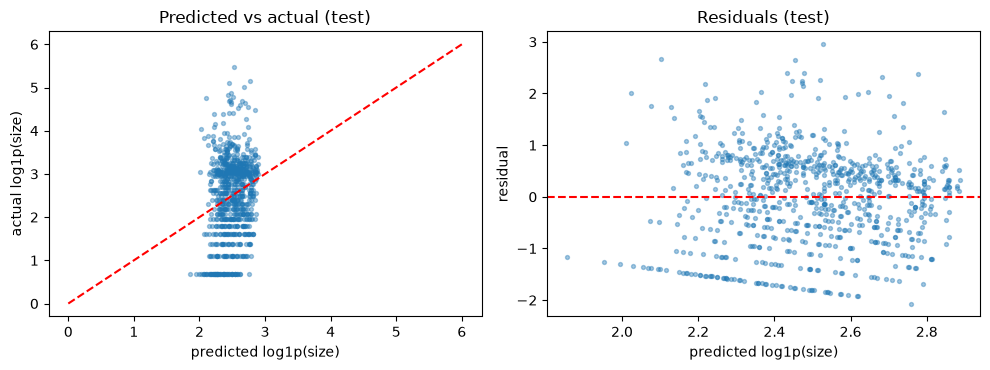

In [11]:
coefs = pd.Series(model.named_steps["ridge"].coef_, index=["log followers (standardised)", "verified"])
print(coefs.round(4).to_string())
print("intercept:", round(float(model.named_steps["ridge"].intercept_), 4))

p_test = model.predict(test[FEATURES])
y_test = np.log1p(test["cascade_size"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(p_test, y_test, s=8, alpha=0.4)
ax[0].plot([0, 6], [0, 6], color="red", linestyle="--")
ax[0].set_xlabel("predicted log1p(size)")
ax[0].set_ylabel("actual log1p(size)")
ax[0].set_title("Predicted vs actual (test)")
ax[1].scatter(p_test, y_test - p_test, s=8, alpha=0.4)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("predicted log1p(size)")
ax[1].set_ylabel("residual")
ax[1].set_title("Residuals (test)")
plt.tight_layout()
plt.show()

## 9. From a number to a spread-risk level

The dashboard shows Low, Moderate or High. Because the cascades in PHEME are small, we do not use fixed thresholds like 1,000 or 10,000. Instead we split the model's **predicted** values on the training set into three equal groups and use those two cut points. Then we check on the test set whether the groups really separate small cascades from big ones.

In [12]:
train_pred = model.predict(train[FEATURES])
t_low, t_high = np.quantile(train_pred, [1 / 3, 2 / 3])


def risk_level(p_log):
    return np.where(p_log < t_low, "Low", np.where(p_log < t_high, "Moderate", "High"))


test_risk = pd.Series(risk_level(p_test), index=test.index, name="risk")
risk_table = (test.groupby(test_risk)["cascade_size"]
              .agg(cascades="size", mean_size="mean", median_size="median")
              .reindex(["Low", "Moderate", "High"]).round(1))
print(f"cut points: predicted size {np.expm1(t_low):.1f} and {np.expm1(t_high):.1f} tweets")
risk_table

cut points: predicted size 10.0 and 12.2 tweets


,cascades,mean_size,median_size
risk,,,
Low,259,14.0,10.0
Moderate,265,19.8,15.0
High,281,18.3,16.0


## 10. Save the model and the report

The `.joblib` file is a dictionary: the fitted pipeline plus the information the backend needs (feature names, risk cut points, library versions). To use it:

```python
art = joblib.load("backend/models/spread_regressor.joblib")
X = pd.DataFrame({"root_user_followers": [450000], "root_user_verified": [1]})
size = float(np.expm1(art["model"].predict(X))[0])
```

In [13]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o


versions = {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}

artifact = {
    "model": model,
    "features": FEATURES,
    "target": "log1p(cascade_size); predicted size = expm1(model.predict(X))",
    "best_alpha": best_alpha,
    "risk_cut_points_log": {"low_below": float(t_low), "high_from": float(t_high)},
    "risk_cut_points_size": {"low_below": float(np.expm1(t_low)), "high_from": float(np.expm1(t_high))},
    "trained_on": "split == 'train'",
    "versions": versions,
}
joblib.dump(artifact, MODELS / "spread_regressor.joblib")

report = {
    "data": {"cascades": len(df), "train": len(train), "val": len(val), "test": len(test),
             "excluded_label": len(extra), "excluded_dup": int((df["split"] == "excluded_dup").sum())},
    "target": "log1p(cascade_size)",
    "features": FEATURES,
    "best_alpha": best_alpha,
    "leakage_check_spearman": corr.to_dict(),
    "results": results.to_dict(orient="index"),
    "experiment_b": exp_b.to_dict(orient="index"),
    "leave_one_event_out": loeo.to_dict(orient="records"),
    "coefficients": coefs.to_dict(),
    "risk_table_test": risk_table.to_dict(orient="index"),
    "risk_cut_points_size": artifact["risk_cut_points_size"],
    "versions": versions,
    "seed": SEED,
}
with open(REPORTS / "spread_metrics.json", "w", encoding="utf-8") as f:
    json.dump(clean(report), f, indent=2)
print("saved:", MODELS / "spread_regressor.joblib")
print("saved:", REPORTS / "spread_metrics.json")

saved: c:\Users\Admin\Documents\COS30049-political-misinfo\backend\models\spread_regressor.joblib
saved: c:\Users\Admin\Documents\COS30049-political-misinfo\backend\reports\spread_metrics.json


In [14]:
# Reload test: this is exactly what the backend will do
art = joblib.load(MODELS / "spread_regressor.joblib")
sample = pd.DataFrame({"root_user_followers": [450_000, 800, 25_000_000],
                       "root_user_verified": [1, 0, 1]})
pred = np.expm1(art["model"].predict(sample))
print(pd.DataFrame({"followers": sample["root_user_followers"],
                    "verified": sample["root_user_verified"],
                    "predicted_cascade_size": pred.round(1),
                    "risk": risk_level(art["model"].predict(sample))}))

   followers  verified  predicted_cascade_size  risk
0     450000         1                    12.8  High
1        800         0                     8.0   Low
2   25000000         1                    17.1  High


## 11. Discussion

**1. Does Ridge beat the baseline?** Only slightly. On the test set Ridge reaches R2 = 0.040 on the log scale, against 0.000 for the "predict the average" baseline, and its average error is 11.3 tweets against 11.5. The rank correlation is 0.157 (0.204 on validation), so the model ranks bigger cascades above smaller ones a little better than chance. In practice it explains only about 4% of the differences between cascades.

**2. Events the model has never seen.** The picture is weaker when a whole event is held out. The mean R2 over the five big events is -0.142, and Ridge is positive only for the Ottawa shooting (0.059). It is worse than the baseline on Germanwings (-0.561 against -0.454) and slightly worse on Ferguson (-0.013 against -0.007), although its average error is a little lower than the baseline in four of the five events. This agrees with the text models in `split_baselines.md`: a model fitted on some events does not carry over to a new one. How large a cascade gets depends mostly on the event itself (the median cascade has 18 tweets in the Sydney siege, 16 in Charlie Hebdo, 6 in Germanwings and only 1 in Gurlitt), and the follower count of one author cannot capture that.

**3. Which feature matters.** Followers carry the signal. The standardised coefficient of log followers is +0.19, which means an author with one standard deviation more (log) followers is predicted to start a cascade about 21% larger. The verified flag is almost zero (0.0005). Verified accounts tend to have many followers, so once the follower count is known the badge adds nothing. We had expected the badge to matter by itself, and the data do not support that. The leakage check in Section 4 also shows why the structural columns had to stay out: depth and reply count correlate 0.84 and 0.79 with the size, while followers correlate only 0.18.

**4. Extra cascades (Experiment B).** Adding the 937 `excluded_label` cascades did not help (test R2 0.030 against 0.040, error 11.35 against 11.29 tweets). They are mostly smaller cascades (median size 9), so the main model keeps the train split only.

**5. Spread-risk levels.** The two cut points fall at predicted sizes of 10.0 and 12.2 tweets, because predictions from two weak features are squeezed around the average. On the test set the median real size is 10 tweets for Low, 15 for Moderate and 16 for High. Low is clearly lower, but Moderate and High are hardly separated (mean size 19.8 against 18.3). The dashboard should therefore show the risk level as a rough indication based on the author's reach, not as a reliable forecast, and Low should be read as "smaller than usual".

**6. Limitations.** Only two author features were available (no engagement rate and no timestamps), the cascades are small (median 12 tweets, largest 346), the data cover a few events from 2014-2015, and the model cannot see what the post says. A natural next step is to add the text embedding of the source tweet, which is known when a user types a claim, and compare it with this model. That is also where the L2 penalty of Ridge would become more useful, since there would be hundreds of inputs. We have not tested this yet.